<a href="https://colab.research.google.com/github/Amulya-Rao-mj/ML2_lab--Amulya-Rao-M-J--4NI23CI013/blob/main/Lab_10_SHAP_LIME.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
!pip install -q shap

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import shap

from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

# Load dataset
data = load_breast_cancer()

X = pd.DataFrame(data.data, columns=data.feature_names)
y = data.target

print("Dataset loaded successfully!")
print("Dataset shape:", X.shape)

display(X.head())

print("\nTarget classes:", data.target_names)
print("\nClass distribution:")
print(pd.Series(y).value_counts())


Dataset loaded successfully!
Dataset shape: (569, 30)


,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst radius,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,25.38,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,24.99,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,...,23.57,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,...,14.91,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,...,22.54,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678



Target classes: ['malignant' 'benign']

Class distribution:
1    357
0    212
Name: count, dtype: int64


Model trained successfully!
Accuracy: 95.61 %

Classification Report:
              precision    recall  f1-score   support

   malignant       0.95      0.93      0.94        42
      benign       0.96      0.97      0.97        72

    accuracy                           0.96       114
   macro avg       0.96      0.95      0.95       114
weighted avg       0.96      0.96      0.96       114



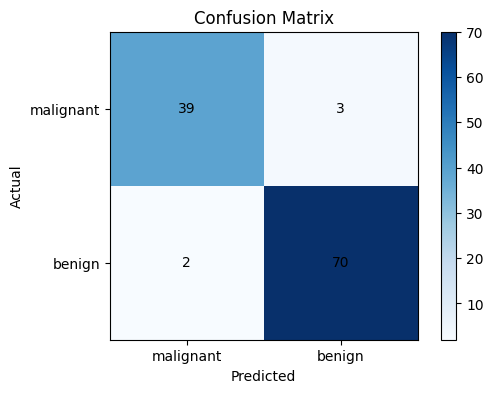

In [2]:
# Split dataset into training and testing
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

# Create Random Forest model
model = RandomForestClassifier(
    n_estimators=100,
    random_state=42
)

# Train model
model.fit(X_train, y_train)

# Make predictions
y_pred = model.predict(X_test)

# Evaluate model
accuracy = accuracy_score(y_test, y_pred)

print("Model trained successfully!")
print("Accuracy:", round(accuracy * 100, 2), "%")

print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred,
    target_names=data.target_names
))

# Confusion matrix
cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(6, 4))
plt.imshow(cm, cmap='Blues')
plt.colorbar()

plt.xticks([0, 1], data.target_names)
plt.yticks([0, 1], data.target_names)

for i in range(2):
    for j in range(2):
        plt.text(j, i, cm[i, j], ha='center', va='center')

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix")
plt.show()


Top 10 Important Features:


,Feature,Importance
23,worst area,0.066893
27,worst concave points,0.063026
20,worst radius,0.048655
22,worst perimeter,0.045389
7,mean concave points,0.041439
6,mean concavity,0.029439
2,mean perimeter,0.027883
0,mean radius,0.026630
26,worst concavity,0.024727
3,mean area,0.023054


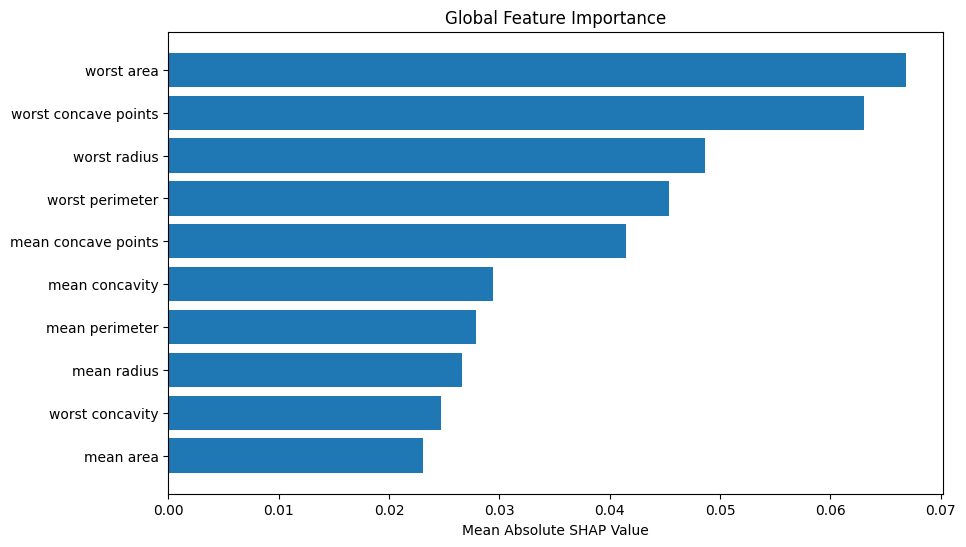

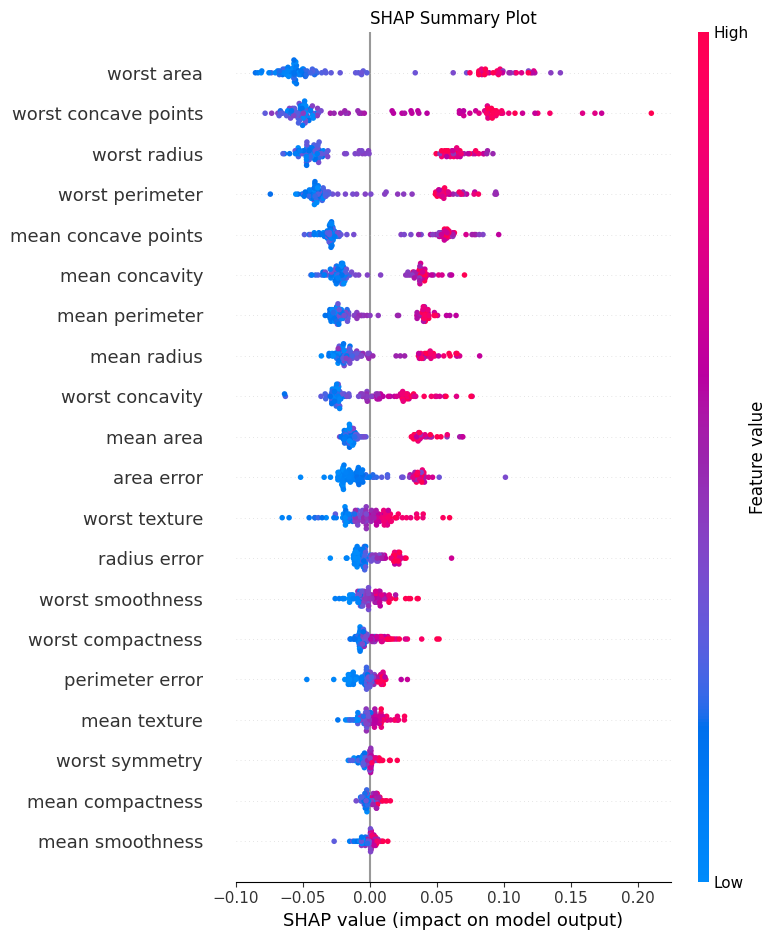


Explaining Test Instance: 1
Actual Diagnosis: malignant
Predicted Diagnosis: malignant
Probability of Malignant: 100.0 %


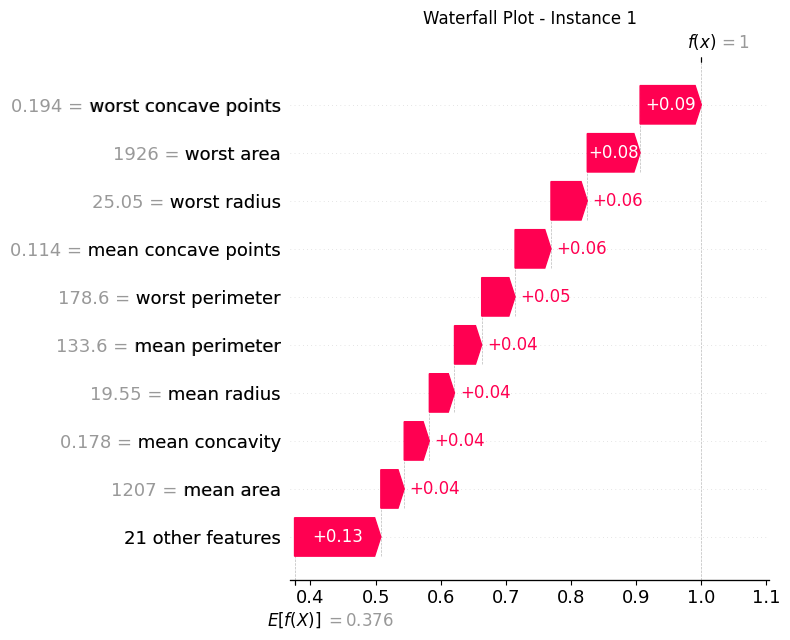


Explaining Test Instance: 2
Actual Diagnosis: benign
Predicted Diagnosis: benign
Probability of Malignant: 0.0 %


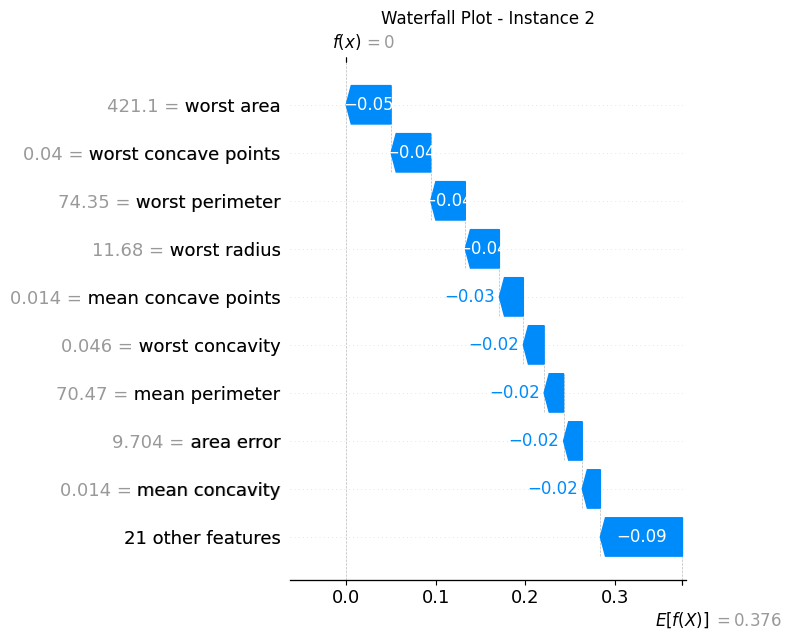

In [4]:
# Create SHAP Tree Explainer
explainer = shap.TreeExplainer(model)

# Calculate SHAP values for test data
shap_values = explainer.shap_values(X_test)

# Select Malignant class (class 0)
if isinstance(shap_values, list):
    malignant_shap = shap_values[0]
elif np.asarray(shap_values).ndim == 3:
    malignant_shap = np.asarray(shap_values)[:, :, 0]
else:
    malignant_shap = np.asarray(shap_values)

# Global feature importance
importance = np.abs(malignant_shap).mean(axis=0)

importance_df = pd.DataFrame({
    'Feature': X.columns,
    'Importance': importance
}).sort_values(by='Importance', ascending=False)

print("Top 10 Important Features:")
display(importance_df.head(10))

# Plot feature importance
plt.figure(figsize=(10, 6))
plt.barh(
    importance_df['Feature'].head(10)[::-1],
    importance_df['Importance'].head(10)[::-1]
)
plt.xlabel("Mean Absolute SHAP Value")
plt.title("Global Feature Importance")
plt.show()
plt.close()

# SHAP summary plot
shap.summary_plot(
    malignant_shap,
    X_test,
    show=False
)
plt.title("SHAP Summary Plot")
plt.tight_layout()
plt.show()
plt.close()

# Explain two individual test instances
for i in range(2):
    print("\n" + "="*40)
    print("Explaining Test Instance:", i + 1)
    print("Actual Diagnosis:", data.target_names[y_test[i]] if hasattr(y_test, 'iloc') else data.target_names[y_test[i]])
    print("Predicted Diagnosis:", data.target_names[y_pred[i]])

    # Use correct indexing for probability prediction
    test_instance = X_test.iloc[[i]]
    prob_malignant = model.predict_proba(test_instance)[0][0]
    print(
        "Probability of Malignant:",
        round(prob_malignant * 100, 2),
        "%"
    )

    # Get expected value for malignant class
    expected = np.asarray(explainer.expected_value).flatten()[0]

    # Create SHAP explanation object for the instance
    explanation = shap.Explanation(
        values=malignant_shap[i],
        base_values=expected,
        data=X_test.iloc[i].values,
        feature_names=X.columns.tolist()
    )

    # Display individual feature contributions cleanly
    plt.figure()
    shap.plots.waterfall(explanation, max_display=10, show=False)
    plt.title(f"Waterfall Plot - Instance {i+1}", fontsize=12)
    plt.tight_layout()
    plt.show()
    plt.close()